<a href="https://colab.research.google.com/github/Matheus-Melo-dos-Santos/DIP-2026.2/blob/main/task_08_salt_pepper_median.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 08: Interactive Salt-and-Pepper Noise Removal

Nesta atividade, você construirá um pipeline interativo para adicionar ruído sal e pimenta a uma imagem grayscale e restaurá-la com um filtro da mediana manual. O ponto principal é explorar a relação entre densidade do ruído e tamanho da janela.

## Roteiro

1. Criar ruído sal e pimenta determinístico.
2. Aplicar a degradação sem modificar a imagem original.
3. Implementar o filtro da mediana com janelas e padding por reflexão.
4. Calcular RMSE.
5. Validar um caso pequeno.
6. Conectar os sliders e explorar densidade versus tamanho da janela.

## 1. Importações

Use apenas NumPy, Matplotlib e ipywidgets. Não use OpenCV, SciPy, scikit-image nem filtros ou geradores prontos.

In [17]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

## 2. Imagem de entrada

A imagem sintética é `uint8` e grayscale. Ela combina um gradiente com um quadrado para tornar bordas e detalhes visíveis durante a filtragem.

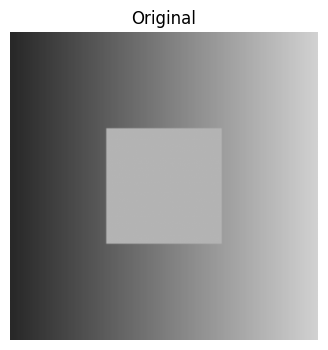

In [18]:
height, width = 128, 128
gradient = np.tile(np.linspace(40, 210, width), (height, 1))
original_image = gradient.astype(np.uint8)
original_image[40:88, 40:88] = 180

plt.figure(figsize=(4, 4))
plt.imshow(original_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")
plt.show()

## 3. Ruído sal e pimenta

Implemente `add_salt_pepper_noise`. A entrada é uma imagem grayscale `uint8` e `density` pertence ao intervalo `[0.0, 1.0]`. Use `rng = np.random.default_rng(seed)` para selecionar os pixels.

Defina quantos pixels serão alterados a partir da densidade e divida-os entre pepper (`0`) e salt (`255`). A imagem original deve permanecer intacta; retorne um novo array `uint8`.

In [19]:
def add_salt_pepper_noise(image, density, seed=0):
    """Adds deterministic salt-and-pepper noise to a grayscale image."""
    noisy_image = None

    ### START CODE HERE ###
    noisy_image = image.copy()
    if density > 0.0:
        rng = np.random.default_rng(seed)
        num_pixels = int(np.round(image.size * density))

        indices = rng.choice(image.size, size=num_pixels, replace=False)

        num_pepper = num_pixels // 2
        pepper_indices = indices[:num_pepper]
        salt_indices = indices[num_pepper:]

        # Converte 1D para 2D
        coords_pepper = np.unravel_index(pepper_indices, image.shape)
        coords_salt = np.unravel_index(salt_indices, image.shape)

        noisy_image[coords_pepper] = 0
        noisy_image[coords_salt] = 255

    ### END CODE HERE ###

    return noisy_image

## 4. Filtro da mediana

Implemente `median_filter` sem usar filtros prontos. `kernel_size` deve ser ímpar e maior ou igual a `3`. Use `np.pad(image, ..., mode="reflect")` para as bordas.

Para cada pixel, extraia manualmente a janela `kernel_size x kernel_size`, calcule `np.median` e armazene o resultado. A saída deve ter o mesmo shape, dtype `uint8` e não pode modificar a entrada.

In [20]:
def median_filter(image, kernel_size):
    """Applies a manual median filter to a grayscale uint8 image."""
    filtered = None

    ### START CODE HERE ###
    if kernel_size < 3 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be odd and at least 3.")

    pad_width = kernel_size // 2
    padded_image = np.pad(image, pad_width, mode="reflect")

    height, width = image.shape
    filtered = np.zeros_like(image)

    for i in range(height):
        for j in range(width):

            window = padded_image[i : i + kernel_size, j : j + kernel_size]
            filtered[i, j] = np.median(window)

    ### END CODE HERE ###

    return filtered

## 5. RMSE

Calcule em `float64` a raiz do erro quadrático médio: `sqrt(mean((reference - result) ** 2))`.

In [21]:
def rmse(reference, result):
    """Calculates root mean squared error using float64 arithmetic."""
    value = None

    ### START CODE HERE ###
    ref_f64 = reference.astype(np.float64)
    res_f64 = result.astype(np.float64)
    value = np.sqrt(np.mean((ref_f64 - res_f64) ** 2))
    ### END CODE HERE ###

    return value

## 6. Teste determinístico

Execute esta célula depois de completar as três funções. Ela verifica repetibilidade, densidade zero, shape, dtype, imutabilidade, janelas `3` e `5`, remoção de impulsos isolados e um RMSE conhecido.

In [22]:
image = np.full((5, 5), 10, dtype=np.uint8)
original = image.copy()

no_noise = add_salt_pepper_noise(image, density=0.0, seed=7)
assert np.array_equal(no_noise, image)
assert no_noise is not image

noisy_first = add_salt_pepper_noise(image, density=0.4, seed=7)
noisy_second = add_salt_pepper_noise(image, density=0.4, seed=7)
assert np.array_equal(noisy_first, noisy_second)
assert np.array_equal(image, original)
assert noisy_first is not image
assert np.count_nonzero(noisy_first == 0) == 5
assert np.count_nonzero(noisy_first == 255) == 5
assert noisy_first.shape == image.shape
assert noisy_first.dtype == np.uint8
noisy_dense = add_salt_pepper_noise(image, density=0.8, seed=7)
assert np.count_nonzero(noisy_dense != image) > np.count_nonzero(noisy_first != image)

salt_impulse = image.copy()
salt_impulse[2, 2] = 255
pepper_impulse = image.copy()
pepper_impulse[2, 2] = 0
filtered_3 = median_filter(salt_impulse, kernel_size=3)
filtered_5 = median_filter(pepper_impulse, kernel_size=5)
assert filtered_3[2, 2] == 10
assert filtered_5[2, 2] == 10
assert filtered_3.shape == image.shape
assert filtered_5.shape == image.shape
assert filtered_3.dtype == np.uint8
assert filtered_5.dtype == np.uint8

median_input = salt_impulse.copy()
median_original = median_input.copy()

median_result = median_filter(
    median_input,
    kernel_size=3,
)

assert np.array_equal(
    median_input,
    median_original,
)

assert median_result is not median_input

border_image = np.array(
    [
        [1, 2, 3],
        [4, 5, 6],
        [7, 8, 9],
    ],
    dtype=np.uint8,
)

border_filtered = median_filter(
    border_image,
    kernel_size=3,
)

assert border_filtered[0, 0] == 4

for invalid_kernel_size in (1, 4):
    try:
        median_filter(
            image,
            kernel_size=invalid_kernel_size,
        )
    except ValueError:
        pass
    else:
        raise AssertionError(
            "kernel_size must be odd and at least 3."
        )

reference = np.zeros((2, 2), dtype=np.uint8)
result = np.full((2, 2), 3, dtype=np.uint8)
assert rmse(reference, result) == 3.0
print("Test passed!")

Test passed!


## 7. Experimento interativo

A função abaixo realiza o pipeline completo. Ela usa seed fixa para que, ao mudar apenas o tamanho da janela, você compare a mesma imagem ruidosa.

In [23]:
def update_pipeline(noise_density, kernel_size):
    noisy = add_salt_pepper_noise(original_image, noise_density, seed=0)
    restored = median_filter(noisy, kernel_size)

    figure, axes = plt.subplots(1, 3, figsize=(12, 4))
    panels = (
        (original_image, "Original"),
        (noisy, "Com ruído"),
        (restored, "Restaurada"),
    )
    for axis, (data, title) in zip(axes, panels, strict=True):
        axis.imshow(data, cmap="gray", vmin=0, vmax=255)
        axis.set_title(title)
        axis.axis("off")
    figure.tight_layout()
    plt.show()
    print(f"RMSE noisy: {rmse(original_image, noisy):.6f}")
    print(f"RMSE restored: {rmse(original_image, restored):.6f}")

## 8. Sliders

O slider de densidade está pronto como exemplo e atualiza continuamente. Crie `kernel_size_slider` com opções ímpares `3`, `5`, `7` e `9`, também com `continuous_update=True`. Em seguida, conecte os dois controles à função `update_pipeline`.

In [24]:
density_slider = widgets.FloatSlider(
    value=0.05,
    min=0.0,
    max=0.30,
    step=0.01,
    description="Density:",
    continuous_update=True,
)

kernel_size_slider = None

### START CODE HERE ###

kernel_size_slider = widgets.SelectionSlider(
    options=[3, 5, 7, 9],
    value=3,
    description="Kernel size:",
    continuous_update=True
)

### END CODE HERE ###

interactive_output = widgets.interactive_output(
    update_pipeline,
    {
        "noise_density": density_slider,
        "kernel_size": kernel_size_slider,
    },
)

display(
    widgets.VBox(
        [
            density_slider,
            kernel_size_slider,
        ]
    ),
    interactive_output,
)

Output()

## Explore

Aumente a densidade e observe mais pixels corrompidos. Compare janelas pequenas e grandes: janelas maiores podem remover mais impulsos, mas também eliminam detalhes e bordas. Aumentar a janela indefinidamente não garante menor RMSE nem melhor aparência visual.